# Netflix Customer Churn - EDA & Insights

**Goal:** find out who churns, why, and how much revenue is at risk.

**Sections:** 1) Data quality & cleaning  2) Churn overview  3) Segment analysis  4) Engagement & inactivity  5) Correlations & leakage check  6) Revenue at risk  7) Key insights

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
df = pd.read_csv('../data/netflix_customer_churn.csv')
df.head()

,customer_id,age,gender,subscription_type,watch_hours,last_login_days,region,device,monthly_fee,churned,payment_method,number_of_profiles,avg_watch_time_per_day,favorite_genre
0,a9b75100-82a8-427a-a208-72f24052884a,51,Other,Basic,14.73,29,Africa,TV,8.99,1,Gift Card,1,0.49,Action
1,49a5dfd9-7e69-4022-a6ad-0a1b9767fb5b,47,Other,Standard,0.70,19,Europe,Mobile,13.99,1,Gift Card,5,0.03,Sci-Fi
2,4d71f6ce-fca9-4ff7-8afa-197ac24de14b,27,Female,Standard,16.32,10,Asia,TV,13.99,0,Crypto,2,1.48,Drama
3,d3c72c38-631b-4f9e-8a0e-de103cad1a7d,53,Other,Premium,4.51,12,Oceania,TV,17.99,1,Crypto,2,0.35,Horror
4,4e265c34-103a-4dbb-9553-76c9aa47e946,56,Other,Standard,1.89,13,Africa,Mobile,13.99,1,Crypto,2,0.13,Action


## 1. Data quality & cleaning

In [2]:
print('Shape:', df.shape)
print('Duplicate rows:', df.duplicated().sum())
print('Duplicate customer_id:', df['customer_id'].duplicated().sum())
print('Missing values:', int(df.isna().sum().sum()))
df.describe().T.round(2)

Shape: (5000, 14)
Duplicate rows: 0
Duplicate customer_id: 0
Missing values: 0


,count,mean,std,min,25%,50%,75%,max
age,5000.0,43.85,15.50,18.00,30.00,44.00,58.00,70.00
watch_hours,5000.0,11.65,12.01,0.01,3.34,8.00,16.03,110.40
last_login_days,5000.0,30.09,17.54,0.00,15.00,30.00,45.00,60.00
monthly_fee,5000.0,13.68,3.69,8.99,8.99,13.99,17.99,17.99
churned,5000.0,0.50,0.50,0.00,0.00,1.00,1.00,1.00
number_of_profiles,5000.0,3.02,1.42,1.00,2.00,3.00,4.00,5.00
avg_watch_time_per_day,5000.0,0.87,2.62,0.00,0.11,0.29,0.72,98.42


In [3]:
# Outlier check using the IQR rule
num_cols = ['age', 'watch_hours', 'last_login_days', 'monthly_fee', 'number_of_profiles', 'avg_watch_time_per_day']
rows = []
for c in num_cols:
    q1, q3 = df[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    n = ((df[c] < q1 - 1.5 * iqr) | (df[c] > q3 + 1.5 * iqr)).sum()
    rows.append((c, n))
pd.DataFrame(rows, columns=['column', 'outliers_iqr'])

,column,outliers_iqr
0,age,0
1,watch_hours,238
2,last_login_days,0
3,monthly_fee,0
4,number_of_profiles,0
5,avg_watch_time_per_day,549


**Finding:** `avg_watch_time_per_day` has values above 24 hours/day, which is physically impossible. Let's look at them.

In [4]:
bad = df[df['avg_watch_time_per_day'] > 24]
print('Rows above 24 h/day:', len(bad))
bad[['watch_hours', 'avg_watch_time_per_day', 'last_login_days', 'churned']]

Rows above 24 h/day: 10


,watch_hours,avg_watch_time_per_day,last_login_days,churned
647,25.15,25.15,0,0
1219,52.80,52.80,0,0
2017,98.42,98.42,0,0
2564,34.53,34.53,0,0
3641,28.66,28.66,0,0
4078,32.81,32.81,0,0
4285,54.53,27.27,1,0
4792,32.88,32.88,0,0
4805,29.55,29.55,0,0
4845,26.98,26.98,0,0


All of these rows have `avg_watch_time_per_day` equal to (or half of) total `watch_hours` and a login within the last day, which looks like a division artefact (hours divided by only 1-2 days of account activity). **Decision:** cap at 24 hours/day (10 of 5,000 rows, 0.2%). The cap is applied in `src/data.py` so the SQL/Python/model results stay consistent.

In [5]:
df['avg_watch_time_per_day'] = df['avg_watch_time_per_day'].clip(upper=24)
print('Max after cap:', df['avg_watch_time_per_day'].max())

Max after cap: 24.0


## 2. Churn overview

In [6]:
churn_rate = df['churned'].mean() * 100
lost = df.loc[df['churned'] == 1, 'monthly_fee'].sum()
print(f'Overall churn rate: {churn_rate:.1f}%  ({df.churned.sum():,} of {len(df):,} customers)')
print(f'Monthly revenue lost to churn: ${lost:,.0f}  (~${lost*12:,.0f}/year)')

Overall churn rate: 50.3%  (2,515 of 5,000 customers)
Monthly revenue lost to churn: $33,010  (~$396,118/year)


## 3. Segment analysis

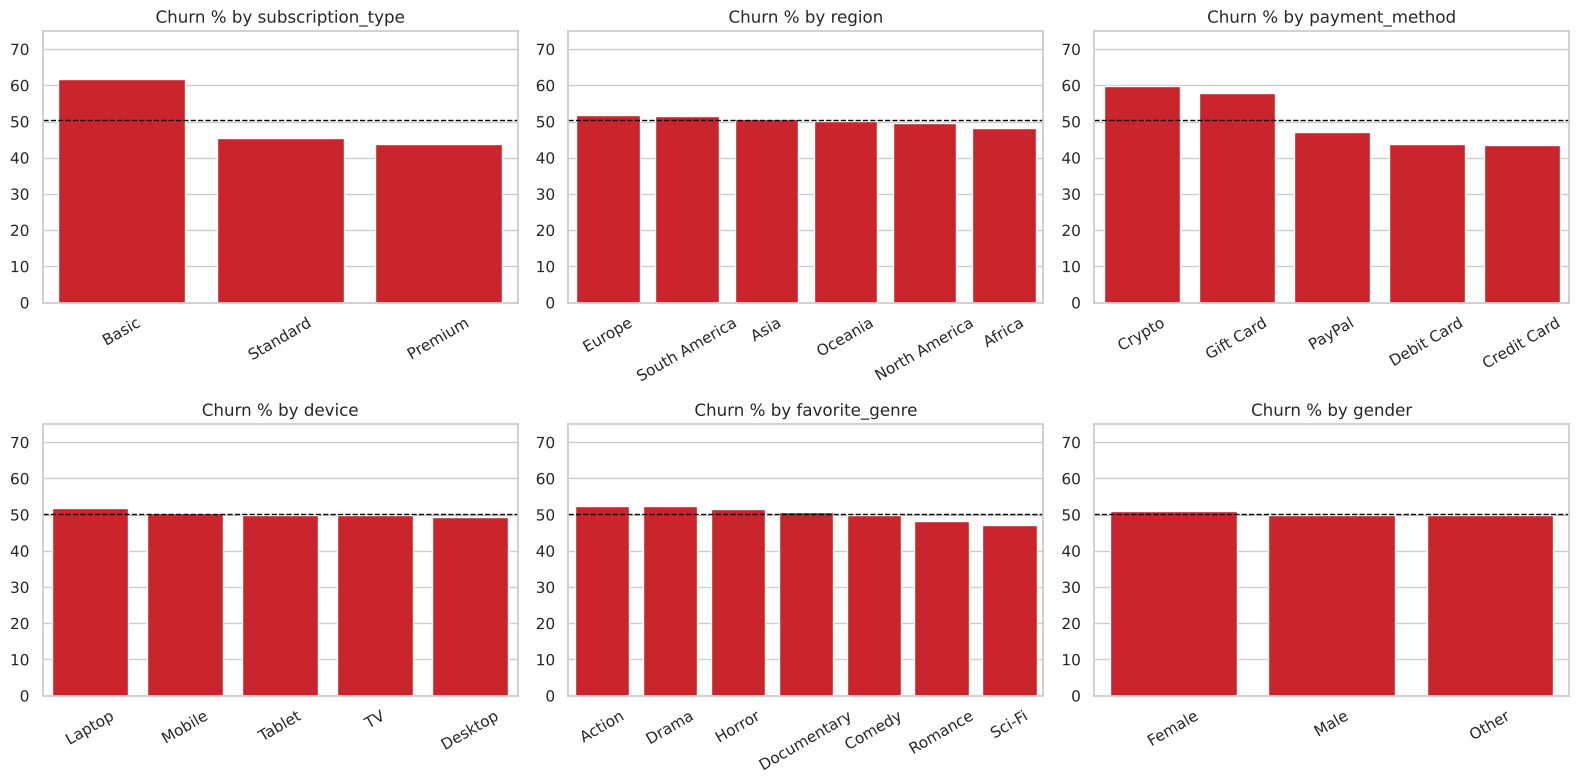

In [7]:
cat_cols = ['subscription_type', 'region', 'payment_method', 'device', 'favorite_genre', 'gender']
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, c in zip(axes.ravel(), cat_cols):
    s = df.groupby(c)['churned'].mean().mul(100).sort_values(ascending=False)
    sns.barplot(x=s.index, y=s.values, ax=ax, color='#E50914')
    ax.axhline(churn_rate, color='black', ls='--', lw=1)
    ax.set_ylim(0, 75)
    ax.set_title(f'Churn % by {c}'); ax.set_xlabel(''); ax.tick_params(axis='x', rotation=30)
plt.tight_layout(); plt.show()

**Insight:** only **subscription plan** and **payment method** move churn meaningfully. Region, device, genre and gender all sit within a few points of the dashed average line, so they are *not* useful targeting levers.

In [8]:
print('Churn % by number of profiles:')
df.groupby('number_of_profiles')['churned'].agg(customers='count', churn_rate_pct=lambda s: round(s.mean()*100, 1))

Churn % by number of profiles:


,customers,churn_rate_pct
number_of_profiles,,
1,972,58.6
2,1001,57.4
3,994,57.8
4,999,37.5
5,1034,40.6


**Insight:** accounts with **4-5 profiles churn far less** (about 38-41%) than accounts with 1-3 profiles (about 57-59%). Shared/household accounts are stickier.

In [9]:
print('Revenue lost to churn by plan (monthly):')
df[df.churned == 1].groupby('subscription_type')['monthly_fee'].agg(churned_customers='count', monthly_revenue_lost='sum').round(0)

Revenue lost to churn by plan (monthly):


,churned_customers,monthly_revenue_lost
subscription_type,,
Basic,1027,9233.0
Premium,740,13313.0
Standard,748,10465.0


**Insight:** Premium has the *lowest* churn rate but the *highest* revenue lost, because each customer pays more. Churn rate alone understates the Premium problem.

## 4. Engagement & inactivity

In [10]:
df['engagement_quartile'] = pd.qcut(df['avg_watch_time_per_day'].rank(method='first'), 4,
                                     labels=['Q1 (lowest)', 'Q2', 'Q3', 'Q4 (highest)'])
df.groupby('engagement_quartile', observed=True)['churned'].agg(
    customers='count', churn_rate_pct=lambda s: round(s.mean() * 100, 1))

,customers,churn_rate_pct
engagement_quartile,,
Q1 (lowest),1250,93.6
Q2,1250,74.4
Q3,1250,32.2
Q4 (highest),1250,1.0


In [11]:
df['inactivity_bucket'] = pd.cut(df['last_login_days'], [-1, 7, 14, 30, np.inf],
                                  labels=['0-7 days', '8-14 days', '15-30 days', '30+ days'])
df.groupby('inactivity_bucket', observed=True)['churned'].agg(
    customers='count', churn_rate_pct=lambda s: round(s.mean() * 100, 1))

,customers,churn_rate_pct
inactivity_bucket,,
0-7 days,650,13.4
8-14 days,559,27.0
15-30 days,1322,32.0
30+ days,2469,75.1


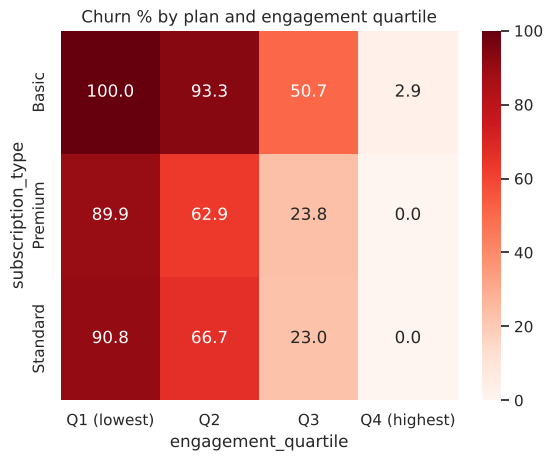

In [12]:
pivot = df.pivot_table(index='subscription_type', columns='engagement_quartile', values='churned',
                       aggfunc='mean', observed=True) * 100
sns.heatmap(pivot, annot=True, fmt='.1f', cmap='Reds')
plt.title('Churn % by plan and engagement quartile'); plt.show()

**Insight:** engagement dominates everything. Churn falls from ~94% in the lowest engagement quartile to ~1% in the highest, and plan matters much less once engagement is held constant.

## 5. Correlations & leakage check

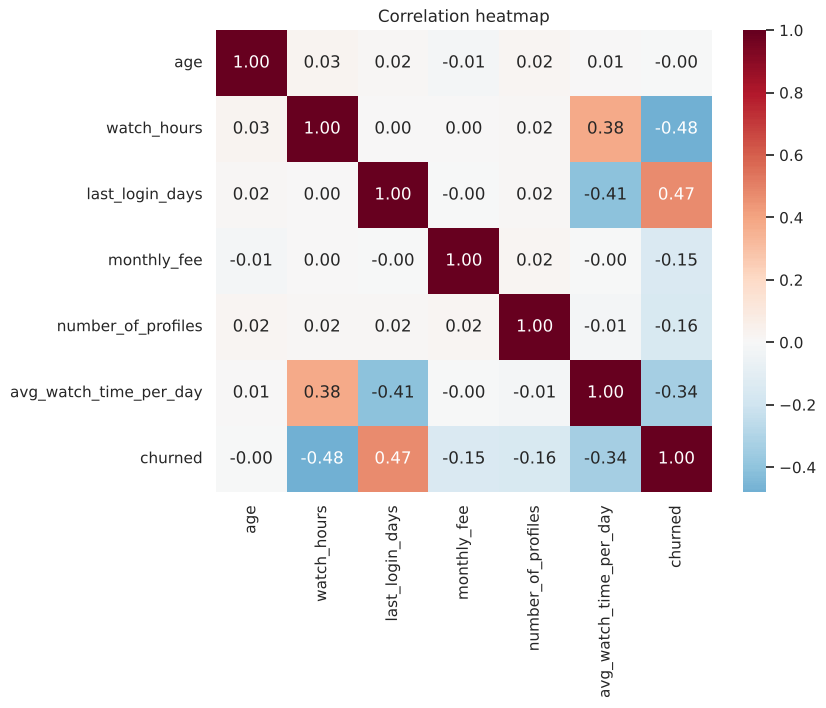

In [13]:
plt.figure(figsize=(8, 6))
sns.heatmap(df[num_cols + ['churned']].corr(), annot=True, fmt='.2f', cmap='RdBu_r', center=0)
plt.title('Correlation heatmap'); plt.show()

In [14]:
from sklearn.metrics import roc_auc_score
ratio = df['watch_hours'] / df['avg_watch_time_per_day'].replace(0, np.nan)
print('watch_hours / avg_watch_time_per_day (implied days) quantiles:')
print(ratio.quantile([.05, .25, .5, .75, .95]).round(1).to_dict())
print()
for c in num_cols:
    a = roc_auc_score(df['churned'], df[c])
    print(f'{c:25s} single-feature AUC = {max(a, 1 - a):.3f}')

watch_hours / avg_watch_time_per_day (implied days) quantiles:
{0.05: 3.0, 0.25: 16.0, 0.5: 30.9, 0.75: 45.9, 0.95: 58.5}

age                       single-feature AUC = 0.502
watch_hours               single-feature AUC = 0.813
last_login_days           single-feature AUC = 0.772
monthly_fee               single-feature AUC = 0.580
number_of_profiles        single-feature AUC = 0.590
avg_watch_time_per_day    single-feature AUC = 0.924


`avg_watch_time_per_day` is essentially `watch_hours` divided by a number of days, so the two are redundant. Its single-feature AUC (~0.92) is high enough to be suspicious. Now test how much of a model's performance comes from the engagement group as a whole:

In [15]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import train_test_split

engagement = ['watch_hours', 'avg_watch_time_per_day', 'last_login_days']
all_feats = [c for c in num_cols] + ['gender', 'subscription_type', 'region', 'device', 'payment_method', 'favorite_genre']

def auc_for(feats):
    X = pd.get_dummies(df[feats], drop_first=True)
    Xtr, Xte, ytr, yte = train_test_split(X, df['churned'], test_size=0.2, stratify=df['churned'], random_state=42)
    m = GradientBoostingClassifier(random_state=42).fit(Xtr, ytr)
    return roc_auc_score(yte, m.predict_proba(Xte)[:, 1])

print('All features:                       ', round(auc_for(all_feats), 4))
print('Without avg_watch_time_per_day only:', round(auc_for([f for f in all_feats if f != 'avg_watch_time_per_day']), 4))
print('Without ALL 3 engagement features:  ', round(auc_for([f for f in all_feats if f not in engagement]), 4))

All features:                        0.9978


Without avg_watch_time_per_day only: 0.9979


Without ALL 3 engagement features:   0.6334


**Conclusion:** dropping one engagement feature changes almost nothing (the others cover for it), but dropping the whole group drops ROC-AUC from ~0.998 to ~0.63. Churn in this dataset is driven almost entirely by engagement, and the near-perfect score reflects a clean, synthetic signal. On real data I would expect much lower performance and would validate on a time-based split.

## 6. Revenue at risk
Active customers with **bottom-half engagement** (quartiles 1-2) who have been **inactive 15+ days**.

In [16]:
profile = df[(df['engagement_quartile'].isin(['Q1 (lowest)', 'Q2'])) & (df['last_login_days'] >= 15)]
print(f'Churn rate of this profile across all customers: {profile.churned.mean()*100:.1f}%  (n={len(profile):,})')
at_risk = profile[profile['churned'] == 0]
print('Active at-risk customers:', len(at_risk))
print(f"Monthly revenue at risk: ${at_risk['monthly_fee'].sum():,.0f}")
print(f"Annual revenue at risk:  ${at_risk['monthly_fee'].sum() * 12:,.0f}")
at_risk.groupby('subscription_type')['monthly_fee'].agg(customers='count', monthly_risk='sum').round(0)

Churn rate of this profile across all customers: 85.2%  (n=2,281)
Active at-risk customers: 337
Monthly revenue at risk: $5,223
Annual revenue at risk:  $62,672


,customers,monthly_risk
subscription_type,,
Basic,28,252.0
Premium,162,2914.0
Standard,147,2057.0


## 7. Key insights

| # | Finding | Evidence | Recommended action |
|---|---|---|---|
| 1 | Engagement is the dominant churn driver | Churn: 93.6% (lowest quartile) → 1.0% (highest) | Track share of low-engagement users weekly as an early-warning KPI |
| 2 | Inactivity cliff after 30 days | 13.4% churn (0-7 days) vs 75.1% (30+ days) | Trigger win-back messages at day 15, before the 30-day cliff |
| 3 | Basic plan churns most | 61.8% vs 43.7% Premium (+18 pts) | Upgrade / bundle offers for Basic users |
| 4 | Crypto & Gift Card payers churn more | 59.7% / 57.8% vs ~43.6% for Credit/Debit (~15 pts) | Incentivise move to auto-renewing card payment |
| 5 | Multi-profile accounts are stickier | 4-5 profiles: 37.5-40.6% vs 1-3 profiles: ~58% | Promote profile creation / family plans |
| 6 | Premium loses the most revenue | $13.3K/month lost despite lowest churn rate | Prioritise Premium retention by revenue, not rate |
| 7 | Retention target list | 337 active at-risk customers, ~$5.2K/month (~$62.7K/year) | Targeted win-back campaign with a control group |
| 8 | Region, device, gender, genre are not drivers | All within ~±3 pts of the 50.3% average | Don't spend effort segmenting on these |
